In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

import joblib

In [2]:
train_df = pd.read_csv(
    "../data/processed/train.csv"
)

validation_df = pd.read_csv(
    "../data/processed/validation.csv"
)

test_df = pd.read_csv(
    "../data/processed/test.csv"
)

print("Train:", train_df.shape)
print("Validation:", validation_df.shape)
print("Test:", test_df.shape)

Train: (6082007, 16)
Validation: (191147, 16)
Test: (89466, 16)


In [3]:
X_train = train_df.drop(columns=["isFraud"])
y_train = train_df["isFraud"]

X_validation = validation_df.drop(columns=["isFraud"])
y_validation = validation_df["isFraud"]

X_test = test_df.drop(columns=["isFraud"])
y_test = test_df["isFraud"]

In [4]:
categorical_features = ["type"]

numeric_features = [
    col
    for col in X_train.columns
    if col not in categorical_features
]

print("Categorical features:")
print(categorical_features)

print("\nNumeric features:")
print(numeric_features)

Categorical features:
['type']

Numeric features:
['step', 'amount', 'oldbalanceOrg', 'oldbalanceDest', 'amount_log', 'amount_to_origin_balance', 'amount_to_dest_balance', 'origin_balance_depletion', 'origin_balance_zero', 'destination_balance_zero', 'hour', 'day', 'hour_sin', 'hour_cos']


In [5]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numeric",
            StandardScaler(),
            numeric_features
        )
    ]
)

In [6]:
X_train_processed = preprocessor.fit_transform(
    X_train
)

X_validation_processed = preprocessor.transform(
    X_validation
)

X_test_processed = preprocessor.transform(
    X_test
)

In [7]:
print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("Original validation shape:", X_validation.shape)
print("Processed validation shape:", X_validation_processed.shape)

Original training shape: (6082007, 15)
Processed training shape: (6082007, 19)
Original validation shape: (191147, 15)
Processed validation shape: (191147, 19)


In [8]:
def evaluate_model(
    y_true,
    probabilities,
    threshold=0.5
):
    predictions = (
        probabilities >= threshold
    ).astype(int)

    precision = precision_score(
        y_true,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        predictions,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y_true,
        probabilities
    )

    pr_auc = average_precision_score(
        y_true,
        probabilities
    )

    return {
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc
    }

In [9]:
logistic_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

logistic_model.fit(
    X_train_processed,
    y_train
)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default 

In [10]:
logistic_validation_prob = (
    logistic_model.predict_proba(
        X_validation_processed
    )[:, 1]
)

In [11]:
logistic_metrics = evaluate_model(
    y_validation,
    logistic_validation_prob
)

logistic_metrics

{'threshold': 0.5,
 'precision': 0.11868839267752967,
 'recall': 1.0,
 'f1': 0.21219205178924655,
 'roc_auc': 0.9977086742898164,
 'pr_auc': 0.8695407633989902}

In [12]:
thresholds = np.arange(0.10, 0.96, 0.05)

threshold_results = []

for threshold in thresholds:

    predictions = (
        logistic_validation_prob >= threshold
    ).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_validation,
            predictions,
            zero_division=0
        ),
        "recall": recall_score(
            y_validation,
            predictions,
            zero_division=0
        ),
        "f1": f1_score(
            y_validation,
            predictions,
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df

,threshold,precision,recall,f1
0,0.10,0.043847,1.000000,0.084010
1,0.15,0.049588,1.000000,0.094491
2,0.20,0.055368,1.000000,0.104926
3,0.25,0.061754,1.000000,0.116325
4,0.30,0.069184,1.000000,0.129414
5,0.35,0.077965,1.000000,0.144652
6,0.40,0.088224,1.000000,0.162144
7,0.45,0.101514,1.000000,0.184317
8,0.50,0.118688,1.000000,0.212192
9,0.55,0.140242,0.993220,0.245780


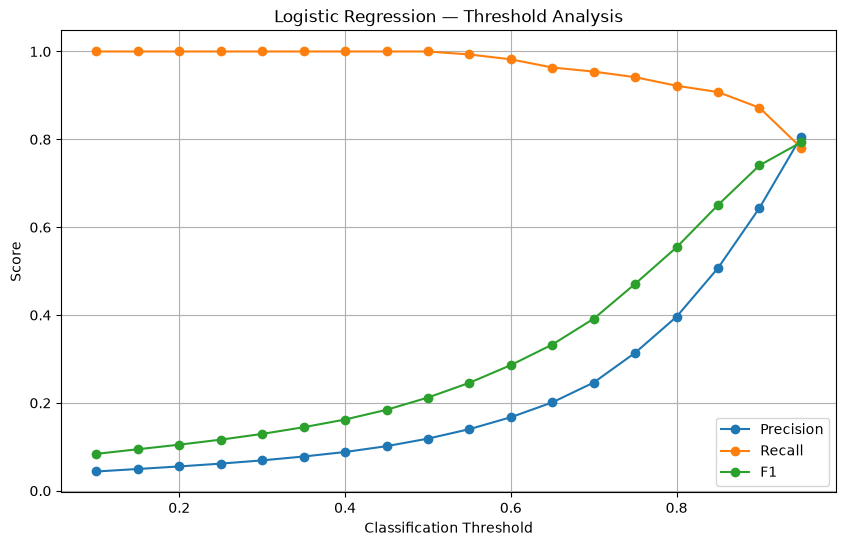

In [13]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["threshold"],
    threshold_df["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["f1"],
    marker="o",
    label="F1"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Logistic Regression — Threshold Analysis")

plt.legend()
plt.grid(True)

plt.show()

In [14]:
best_f1_row = threshold_df.loc[
    threshold_df["f1"].idxmax()
]

print(best_f1_row)

threshold    0.950000
precision    0.805240
recall       0.781356
f1           0.793118
Name: 17, dtype: float64


In [15]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(
    max_depth=12,
    min_samples_leaf=50,
    class_weight="balanced",
    random_state=42
)

tree_model.fit(
    X_train_processed,
    y_train
)

print("✅ Decision Tree trained successfully!")

✅ Decision Tree trained successfully!


In [16]:
tree_validation_prob = (
    tree_model.predict_proba(
        X_validation_processed
    )[:, 1]
)

print("Generated probabilities:", len(tree_validation_prob))

Generated probabilities: 191147


In [17]:
tree_metrics = evaluate_model(
    y_validation,
    tree_validation_prob
)

print(tree_metrics)

{'threshold': 0.5, 'precision': 0.7143727161997564, 'recall': 0.9940677966101695, 'f1': 0.8313253012048193, 'roc_auc': 0.996933972385748, 'pr_auc': 0.9765136145558622}


In [18]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=20,
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=42
)

rf_model.fit(
    X_train_processed,
    y_train
)

print("✅ Random Forest trained successfully!")

✅ Random Forest trained successfully!


In [19]:
rf_validation_prob = (
    rf_model.predict_proba(
        X_validation_processed
    )[:, 1]
)

print(
    "Generated probabilities:",
    len(rf_validation_prob)
)

Generated probabilities: 191147


In [20]:
rf_metrics = evaluate_model(
    y_validation,
    rf_validation_prob
)

print(rf_metrics)

{'threshold': 0.5, 'precision': 0.9932659932659933, 'recall': 1.0, 'f1': 0.9966216216216216, 'roc_auc': 0.9999988088921422, 'pr_auc': 0.9998001107805308}


In [21]:
results = pd.DataFrame([
    logistic_metrics,
    tree_metrics,
    rf_metrics
])

results.insert(
    0,
    "model",
    [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ]
)

results_sorted = results.sort_values(
    "pr_auc",
    ascending=False
)

results_sorted

,model,threshold,precision,recall,f1,roc_auc,pr_auc
2,Random Forest,0.5,0.993266,1.000000,0.996622,0.999999,0.999800
1,Decision Tree,0.5,0.714373,0.994068,0.831325,0.996934,0.976514
0,Logistic Regression,0.5,0.118688,1.000000,0.212192,0.997709,0.869541


In [22]:
import sys

print(sys.executable)

c:\Users\heman\anaconda3\python.exe


In [23]:
import xgboost as xgb

print("XGBoost version:", xgb.__version__)

XGBoost version: 3.4.1


In [24]:
import xgboost as xgb

print("XGBoost version:", xgb.__version__)

XGBoost version: 3.4.1


In [25]:
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Legitimate transactions:", negative_count)
print("Fraud transactions:", positive_count)
print("Scale Pos Weight:", scale_pos_weight)

Legitimate transactions: 6076226
Fraud transactions: 5781
Scale Pos Weight: 1051.0683272790175


In [26]:
xgb_model = xgb.XGBClassifier(
    n_estimators=500,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    objective="binary:logistic",
    eval_metric="aucpr",
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    n_jobs=-1
)

In [27]:
xgb_model.fit(
    X_train_processed,
    y_train,
    eval_set=[(X_validation_processed, y_validation)],
    verbose=False
)

print("XGBoost training completed!")

XGBoost training completed!


In [28]:
xgb_validation_prob = xgb_model.predict_proba(
    X_validation_processed
)[:, 1]

print(xgb_validation_prob[:10])

[0.99999344 0.9999269  0.99999976 0.99999857 0.99999654 0.999889
 0.9999968  0.9998869  0.99999833 0.9999832 ]


In [29]:
xgb_metrics = evaluate_model(
    y_validation,
    xgb_validation_prob
)

xgb_metrics

{'threshold': 0.5,
 'precision': 0.9394904458598726,
 'recall': 1.0,
 'f1': 0.9688013136288999,
 'roc_auc': 0.9999771168997863,
 'pr_auc': 0.9961904308872876}

In [30]:
comparison_df = pd.DataFrame([
    {
        "model": "Logistic Regression",
        **logistic_metrics
    },
    {
        "model": "Decision Tree",
        **tree_metrics
    },
    {
        "model": "Random Forest",
        **rf_metrics
    },
    {
        "model": "XGBoost",
        **xgb_metrics
    }
])

comparison_df = comparison_df[
    ["model", "threshold", "precision", "recall", "f1", "roc_auc", "pr_auc"]
]

comparison_df.sort_values("pr_auc", ascending=False)


,model,threshold,precision,recall,f1,roc_auc,pr_auc
2,Random Forest,0.5,0.993266,1.000000,0.996622,0.999999,0.999800
3,XGBoost,0.5,0.939490,1.000000,0.968801,0.999977,0.996190
1,Decision Tree,0.5,0.714373,0.994068,0.831325,0.996934,0.976514
0,Logistic Regression,0.5,0.118688,1.000000,0.212192,0.997709,0.869541


In [31]:
import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.arange(0.10, 0.96, 0.05)

rf_threshold_results = []

for threshold in thresholds:
    predictions = (rf_validation_prob >= threshold).astype(int)

    rf_threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_validation,
            predictions,
            zero_division=0
        ),
        "recall": recall_score(
            y_validation,
            predictions,
            zero_division=0
        ),
        "f1": f1_score(
            y_validation,
            predictions,
            zero_division=0
        )
    })

rf_threshold_df = pd.DataFrame(rf_threshold_results)

rf_threshold_df

,threshold,precision,recall,f1
0,0.10,0.287594,1.000000,0.446716
1,0.15,0.440299,1.000000,0.611399
2,0.20,0.633727,1.000000,0.775805
3,0.25,0.832158,1.000000,0.908391
4,0.30,0.924765,1.000000,0.960912
5,0.35,0.975207,1.000000,0.987448
6,0.40,0.987448,1.000000,0.993684
7,0.45,0.992431,1.000000,0.996201
8,0.50,0.993266,1.000000,0.996622
9,0.55,0.994941,1.000000,0.997464


In [32]:
xgb_threshold_results = []

for threshold in thresholds:
    predictions = (xgb_validation_prob >= threshold).astype(int)

    xgb_threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_validation,
            predictions,
            zero_division=0
        ),
        "recall": recall_score(
            y_validation,
            predictions,
            zero_division=0
        ),
        "f1": f1_score(
            y_validation,
            predictions,
            zero_division=0
        )
    })

xgb_threshold_df = pd.DataFrame(xgb_threshold_results)

xgb_threshold_df

,threshold,precision,recall,f1
0,0.10,0.932070,1.000000,0.964841
1,0.15,0.932806,1.000000,0.965235
2,0.20,0.933544,1.000000,0.965630
3,0.25,0.935024,1.000000,0.966421
4,0.30,0.937997,1.000000,0.968007
5,0.35,0.938743,1.000000,0.968404
6,0.40,0.938743,1.000000,0.968404
7,0.45,0.939490,1.000000,0.968801
8,0.50,0.939490,1.000000,0.968801
9,0.55,0.939490,1.000000,0.968801


In [33]:
best_rf_threshold = rf_threshold_df.loc[
    rf_threshold_df["f1"].idxmax()
]

best_xgb_threshold = xgb_threshold_df.loc[
    xgb_threshold_df["f1"].idxmax()
]

print("Random Forest:")
print(best_rf_threshold)

print("\nXGBoost:")
print(best_xgb_threshold)

Random Forest:
threshold    0.650000
precision    0.996619
recall       0.999153
f1           0.997884
Name: 11, dtype: float64

XGBoost:
threshold    0.950000
precision    0.944667
recall       0.998305
f1           0.970746
Name: 17, dtype: float64


In [34]:
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.52.0


In [35]:
explainer = shap.TreeExplainer(rf_model)

print("SHAP explainer created successfully!")

SHAP explainer created successfully!


In [36]:
sample_size = min(2000, X_validation_processed.shape[0])

X_shap_sample = X_validation_processed[:sample_size]

shap_values = explainer.shap_values(X_shap_sample)

print("SHAP values calculated!")

SHAP values calculated!


In [37]:
print(type(shap_values))
print(np.array(shap_values).shape)

<class 'numpy.ndarray'>
(2000, 19, 2)


In [38]:
shap_fraud_values = shap_values[:, :, 1]

print("Fraud SHAP shape:", shap_fraud_values.shape)

Fraud SHAP shape: (2000, 19)


In [39]:
feature_names = preprocessor.get_feature_names_out()

print("Number of features:", len(feature_names))
print(feature_names)

Number of features: 19
['categorical__type_CASH_IN' 'categorical__type_CASH_OUT'
 'categorical__type_DEBIT' 'categorical__type_PAYMENT'
 'categorical__type_TRANSFER' 'numeric__step' 'numeric__amount'
 'numeric__oldbalanceOrg' 'numeric__oldbalanceDest' 'numeric__amount_log'
 'numeric__amount_to_origin_balance' 'numeric__amount_to_dest_balance'
 'numeric__origin_balance_depletion' 'numeric__origin_balance_zero'
 'numeric__destination_balance_zero' 'numeric__hour' 'numeric__day'
 'numeric__hour_sin' 'numeric__hour_cos']


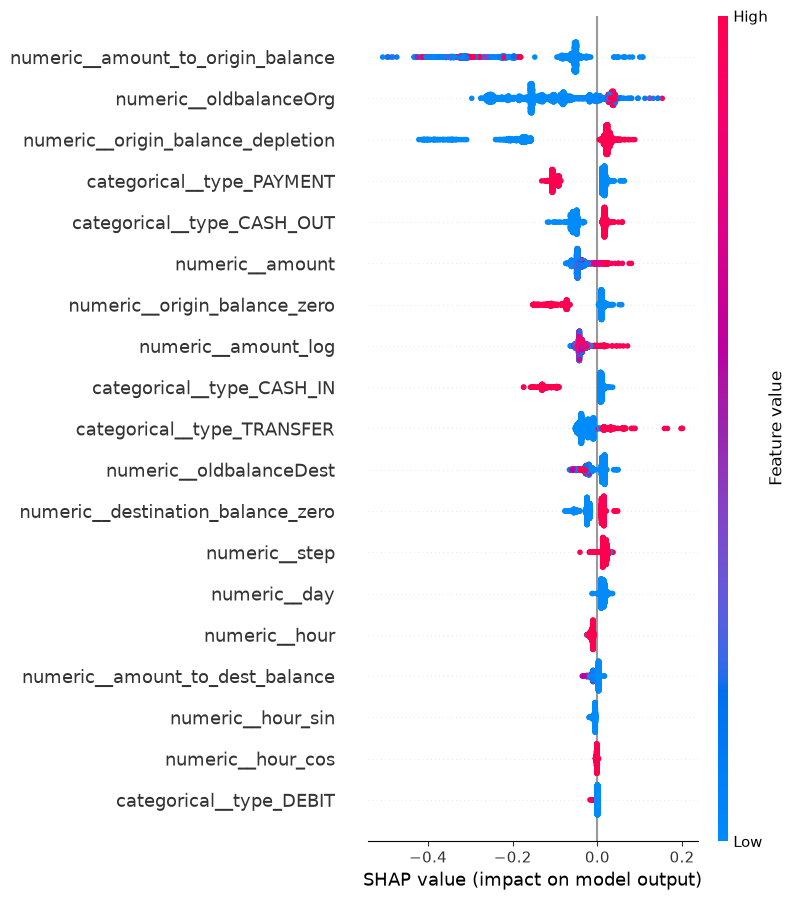

In [40]:
shap.summary_plot(
    shap_fraud_values,
    X_shap_sample,
    feature_names=feature_names
)

In [41]:
shap_importance = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": np.abs(shap_fraud_values).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

shap_importance.head(10)

,feature,mean_abs_shap
0,numeric__amount_to_origin_balance,0.130075
1,numeric__oldbalanceOrg,0.114639
2,numeric__origin_balance_depletion,0.082432
3,categorical__type_PAYMENT,0.045596
4,categorical__type_CASH_OUT,0.042734
5,numeric__amount,0.041401
6,numeric__origin_balance_zero,0.040364
7,numeric__amount_log,0.036561
8,categorical__type_CASH_IN,0.032737
9,categorical__type_TRANSFER,0.028185


In [42]:
fraud_indices = np.where(
    y_validation.to_numpy() == 1
)[0]

print("Fraud transactions available:", len(fraud_indices))

Fraud transactions available: 1180


In [43]:
transaction_idx = fraud_indices[0]

print("Transaction index:", transaction_idx)
print("Actual label:", y_validation.iloc[transaction_idx])
print("Predicted probability:", rf_validation_prob[transaction_idx])

Transaction index: 0
Actual label: 1
Predicted probability: 0.9893630659424035


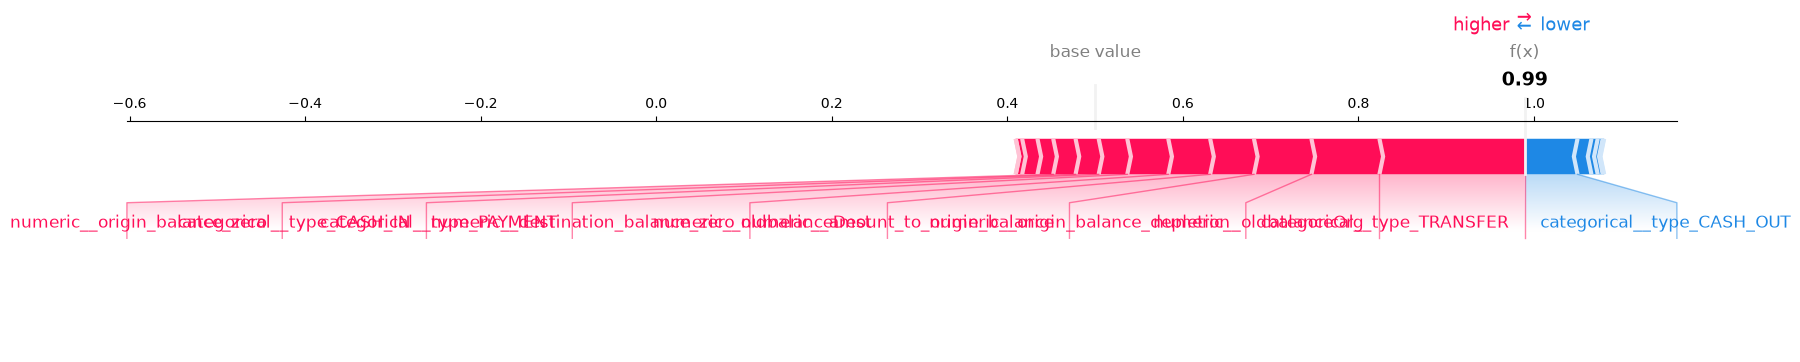

In [44]:
shap.force_plot(
    explainer.expected_value[1],
    shap_fraud_values[transaction_idx],
    feature_names=feature_names,
    matplotlib=True
)

In [45]:
clean_feature_names = [
    name.replace("numeric__", "")
        .replace("categorical__type_", "type_")
    for name in feature_names
]

print(clean_feature_names)

['type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER', 'step', 'amount', 'oldbalanceOrg', 'oldbalanceDest', 'amount_log', 'amount_to_origin_balance', 'amount_to_dest_balance', 'origin_balance_depletion', 'origin_balance_zero', 'destination_balance_zero', 'hour', 'day', 'hour_sin', 'hour_cos']


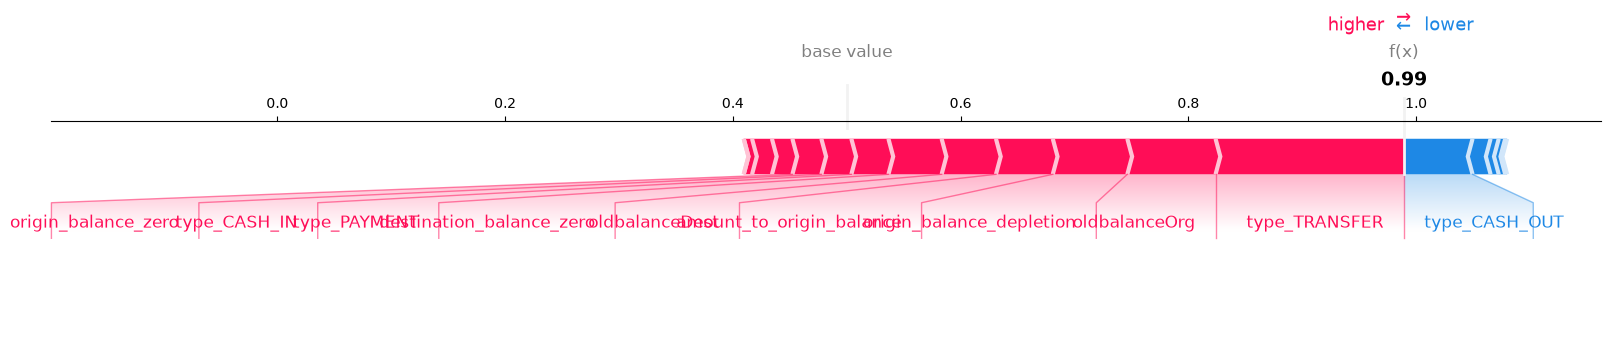

In [46]:
shap.force_plot(
    explainer.expected_value[1],
    shap_fraud_values[transaction_idx],
    feature_names=clean_feature_names,
    matplotlib=True
)

In [47]:
shap_importance = pd.DataFrame({
    "feature": clean_feature_names,
    "mean_abs_shap": np.abs(shap_fraud_values).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

shap_importance.head(10)

,feature,mean_abs_shap
0,amount_to_origin_balance,0.130075
1,oldbalanceOrg,0.114639
2,origin_balance_depletion,0.082432
3,type_PAYMENT,0.045596
4,type_CASH_OUT,0.042734
5,amount,0.041401
6,origin_balance_zero,0.040364
7,amount_log,0.036561
8,type_CASH_IN,0.032737
9,type_TRANSFER,0.028185


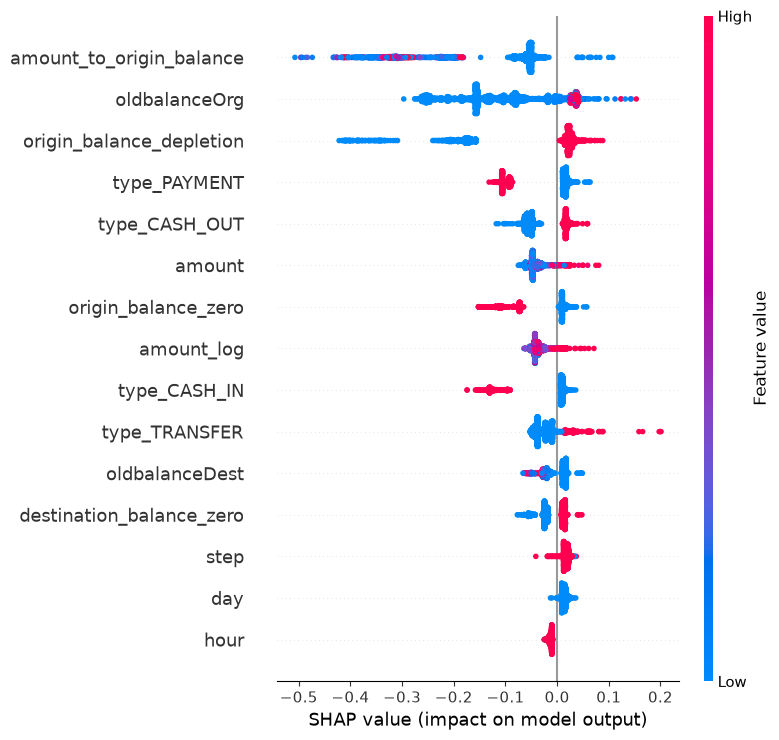

In [48]:
shap.summary_plot(
    shap_fraud_values,
    X_shap_sample,
    feature_names=clean_feature_names,
    max_display=15
)

In [50]:
import pandas as pd
import numpy as np

features = pd.read_csv(
    "../data/processed/authorization_features_v1.csv"
)

print("Features loaded successfully!")
print("Shape:", features.shape)

C:\Users\heman\AppData\Local\Temp\ipykernel_2072\3128052716.py:4: DtypeWarning: Columns (0: prev_origin_type) have mixed types. Specify dtype option on import or set low_memory=False.
  features = pd.read_csv(


Features loaded successfully!
Shape: (6362620, 36)


In [51]:
required_columns = [
    "isFraud",
    "origin_balance_depletion",
    "origin_balance_zero",
    "destination_balance_zero",
    "amount_to_origin_balance",
    "amount_to_dest_balance"
]

print(features[required_columns].head())

   isFraud  origin_balance_depletion  origin_balance_zero  \
0        0                         0                    0   
1        0                         0                    0   
2        1                         1                    0   
3        1                         1                    0   
4        0                         0                    0   

   destination_balance_zero  amount_to_origin_balance  amount_to_dest_balance  
0                         1                  0.057834                0.000000  
1                         1                  0.087735                0.000000  
2                         1                  1.000000                0.000000  
3                         0                  1.000000                0.008545  
4                         1                  0.280795                0.000000  


In [52]:
balance_audit = (
    features
    .groupby("isFraud")[
        [
            "origin_balance_depletion",
            "origin_balance_zero",
            "destination_balance_zero",
            "amount_to_origin_balance",
            "amount_to_dest_balance"
        ]
    ]
    .agg(["mean", "median"])
)

print(balance_audit.round(4))

        origin_balance_depletion        origin_balance_zero         \
                            mean median                mean median   
isFraud                                                              
0                         0.6419    1.0              0.3309    0.0   
1                         0.9817    1.0              0.0050    0.0   

        destination_balance_zero        amount_to_origin_balance          \
                            mean median                     mean  median   
isFraud                                                                    
0                         0.4248    0.0                  81.8178  0.0761   
1                         0.6515    1.0                   0.9938  1.0000   

        amount_to_dest_balance          
                          mean  median  
isFraud                                 
0                       5.8998  0.0284  
1                      24.3566  0.0000  


In [53]:
robust_features = [
    "step",
    "type",
    "amount",
    "oldbalanceOrg",
    "oldbalanceDest",
    "amount_log",
    "hour",
    "day",
    "hour_sin",
    "hour_cos"
]

robust_model_df = features[
    robust_features + ["isFraud"]
].copy()

print("Robust dataset shape:", robust_model_df.shape)

Robust dataset shape: (6362620, 11)


In [54]:
unique_steps = np.sort(robust_model_df["step"].unique())

train_cutoff = int(len(unique_steps) * 0.70)
validation_cutoff = int(len(unique_steps) * 0.85)

train_steps = unique_steps[:train_cutoff]
validation_steps = unique_steps[train_cutoff:validation_cutoff]
test_steps = unique_steps[validation_cutoff:]

robust_train_df = robust_model_df[
    robust_model_df["step"].isin(train_steps)
].copy()

robust_validation_df = robust_model_df[
    robust_model_df["step"].isin(validation_steps)
].copy()

robust_test_df = robust_model_df[
    robust_model_df["step"].isin(test_steps)
].copy()

In [55]:
X_robust_train = robust_train_df.drop(columns=["isFraud"])
y_robust_train = robust_train_df["isFraud"]

X_robust_validation = robust_validation_df.drop(columns=["isFraud"])
y_robust_validation = robust_validation_df["isFraud"]

X_robust_test = robust_test_df.drop(columns=["isFraud"])
y_robust_test = robust_test_df["isFraud"]

In [56]:
robust_categorical = ["type"]

robust_numeric = [
    col for col in X_robust_train.columns
    if col not in robust_categorical
]

robust_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            robust_categorical
        ),
        (
            "numeric",
            StandardScaler(),
            robust_numeric
        )
    ]
)

X_robust_train_processed = robust_preprocessor.fit_transform(
    X_robust_train
)

X_robust_validation_processed = robust_preprocessor.transform(
    X_robust_validation
)

In [57]:
robust_rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=20,
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=42
)

robust_rf_model.fit(
    X_robust_train_processed,
    y_robust_train
)

robust_rf_validation_prob = (
    robust_rf_model
    .predict_proba(X_robust_validation_processed)[:, 1]
)

robust_rf_metrics = evaluate_model(
    y_robust_validation,
    robust_rf_validation_prob
)

print(robust_rf_metrics)

{'threshold': 0.5, 'precision': 0.4637870855148342, 'recall': 0.9008474576271186, 'f1': 0.6123271889400922, 'roc_auc': 0.9976835338840742, 'pr_auc': 0.8822231284666793}


In [58]:
FINAL_THRESHOLD = 0.65

print("Final threshold locked:", FINAL_THRESHOLD)

Final threshold locked: 0.65


In [59]:
rf_test_prob = (
    rf_model
    .predict_proba(X_test_processed)[:, 1]
)

print("Test probabilities generated:", len(rf_test_prob))

Test probabilities generated: 89466


In [60]:
FINAL_THRESHOLD = 0.65

rf_test_predictions = (
    rf_test_prob >= FINAL_THRESHOLD
).astype(int)

print("Test predictions generated!")
print("Fraud predictions:", rf_test_predictions.sum())
print("Legitimate predictions:", len(rf_test_predictions) - rf_test_predictions.sum())

Test predictions generated!
Fraud predictions: 1249
Legitimate predictions: 88217


In [61]:
final_test_metrics = evaluate_model(
    y_test,
    rf_test_prob,
    threshold=FINAL_THRESHOLD
)

final_test_metrics

{'threshold': 0.65,
 'precision': 0.9983987189751802,
 'recall': 0.9960063897763578,
 'f1': 0.9972011195521792,
 'roc_auc': 0.9999956357944819,
 'pr_auc': 0.9997284120749642}

In [62]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    rf_test_predictions
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[88212     2]
 [    5  1247]]


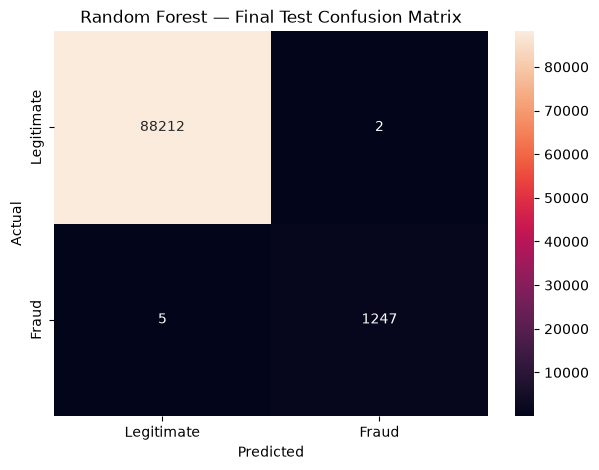

In [63]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest — Final Test Confusion Matrix")

plt.show()

In [64]:
validation_vs_test = pd.DataFrame({
    "metric": [
        "precision",
        "recall",
        "f1",
        "roc_auc",
        "pr_auc"
    ],
    "validation": [
        0.996619,
        0.999153,
        0.997884,
        rf_metrics["roc_auc"],
        rf_metrics["pr_auc"]
    ],
    "test": [
        final_test_metrics["precision"],
        final_test_metrics["recall"],
        final_test_metrics["f1"],
        final_test_metrics["roc_auc"],
        final_test_metrics["pr_auc"]
    ]
})

validation_vs_test

,metric,validation,test
0,precision,0.996619,0.998399
1,recall,0.999153,0.996006
2,f1,0.997884,0.997201
3,roc_auc,0.999999,0.999996
4,pr_auc,0.999800,0.999728


In [65]:
def make_risk_decision(
    fraud_probability,
    review_threshold=0.30,
    block_threshold=0.65
):
    if fraud_probability >= block_threshold:
        return "BLOCK"

    elif fraud_probability >= review_threshold:
        return "REVIEW"

    else:
        return "APPROVE"

In [66]:
test_probabilities = [
    0.05,
    0.25,
    0.40,
    0.64,
    0.65,
    0.90,
    0.99
]

for probability in test_probabilities:
    decision = make_risk_decision(probability)

    print(
        f"Fraud probability: {probability:.2f} "
        f"→ Decision: {decision}"
    )

Fraud probability: 0.05 → Decision: APPROVE
Fraud probability: 0.25 → Decision: APPROVE
Fraud probability: 0.40 → Decision: REVIEW
Fraud probability: 0.64 → Decision: REVIEW
Fraud probability: 0.65 → Decision: BLOCK
Fraud probability: 0.90 → Decision: BLOCK
Fraud probability: 0.99 → Decision: BLOCK


In [67]:
import joblib
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(exist_ok=True)

joblib.dump(
    rf_model,
    MODEL_DIR / "random_forest_fraud_model.joblib"
)

joblib.dump(
    preprocessor,
    MODEL_DIR / "preprocessor.joblib"
)

print("Model and preprocessor saved successfully!")

Model and preprocessor saved successfully!
